# Machine Learning Final Project: 
## Neuro-Symbolic Differentiable Rule Extractor (NSDRE)

**Creator**: Iman Sharifi, G46454668

In [1]:
import numpy as np
import torch
import torch.nn.functional as F

def interpret_neuron_weights_entropy_(body_preds, pred_values, Weights, entropy_threshold=0.8):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        body_preds (list): A list of predicate strings for each neuron, like ['b1', 'b2', ...] or ['b1(X1, X2)', 'b2(X3)', ...]
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    
    interpretations = []
    for i, weights in enumerate(Weights):
        weights_tensor = torch.tensor(weights, dtype=torch.float32)
        entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
        # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

        if entropy > entropy_threshold:
            interpretations.append('?')
            continue

        # Find predicate value of a given neuron
        pred_value = pred_values[i]
        body_pred = body_preds[i]

        # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'{body_pred}')
            continue
        elif max_index == 1:
            interpretations.append(f'not({body_pred})')
            continue
        else:
            interpretations.append('1')

    return interpretations

def interpret_neuron_weights_entropy(pred_values, Weights, entropy_threshold=0.8):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1',
    only if entropy is below a threshold to ensure confidence in prediction.

    Args:
        pred_values (numpy.ndarray): A 1D array with predicate values (between 0 and 1).
        Weights (list of list): A 2D list where each row is the softmaxed weights of a neuron.
        entropy_threshold (float): The threshold of entropy above which output is considered uncertain.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron, or '?' for uncertain.
    """
    interpretations = []
    for i, weights in enumerate(Weights):
        weights_tensor = torch.tensor(weights, dtype=torch.float32)
        entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
        # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

        if entropy > entropy_threshold:
            interpretations.append('?')
            continue

        pred_value = pred_values[i]
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]
        max_index = np.argmax(new_weights)

        if max_index == 0:
            interpretations.append(f'b{i+1}')
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
        else:
            interpretations.append('1')

    return interpretations

def interpret_neuron_weights_(pred_values, Weights):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    

    interpretations = []
    for i, weights in enumerate(Weights):

        # Find predicate value of a given neuron
        pred_value = pred_values[i]

        # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'b{i+1}')
            continue
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
            continue
        else:
            interpretations.append('1')

    return interpretations

def interpret_neuron_weights(Weights):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    

    interpretations = []
    for i, weights in enumerate(Weights):

        # compute {weights[0], weights[1], weights[2]}
        new_weights = [weights[0], weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'b{i+1}')
            continue
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
            continue
        else:
            interpretations.append('1')
    return interpretations

## Learning desire rules from posivitive and negative examples and boolean inputs

## Learning diverse rules using NSDRE

Example rule: 

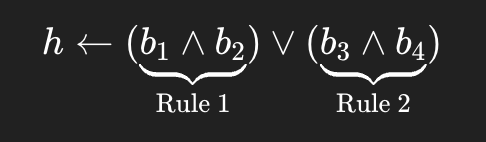

$h \leftarrow h_1 \vee h_2$

$h_1 \leftarrow b_1 \wedge b_2$

$h_2 \leftarrow b_3 \wedge b_4$

Considering a simple Fuzzy Disjunction Layer (like DFORL paper) -> didn't work

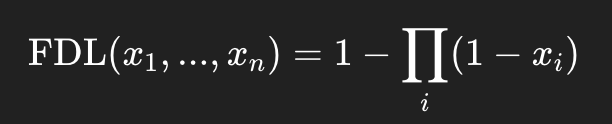

## Network

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 10.0  # Example value for beta
# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(5*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(5*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum

        return activated_output

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt

# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(activated_input)

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])
        self.raw_sigmoid_center_weight = nn.Parameter(torch.randn(num_rules) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []
        self.adjust_sigmoid_center = 0.5 * torch.sigmoid(self.raw_sigmoid_center_weight)  # Ensure sigmoid center is between 0 and 0.5

        for i, rule in enumerate(self.rules):
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            Sum_third_weights = 0.0
            for j, neuron in enumerate(rule):
                xi = x[:, [j % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                with torch.no_grad():
                    Sum_third_weights += weights[2]
            Sum_third_weights = np.round(Sum_third_weights.detach().cpu().numpy(), 0)
            Sum_third_weights = max(Sum_third_weights, 1)
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            rule_output = torch.exp(sum(conjunctions))
            # activated_rule_output = torch.sigmoid(5 * (rule_output - 1 / 2**(self.input_dim - Sum_third_weights)))
            activated_rule_output = torch.sigmoid(5 * (rule_output - self.adjust_sigmoid_center[i]))
            rule_outputs.append(activated_rule_output)

        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r

        return fuzzy_or

## The most stable version of the code:

1 - Added Multiple Initial values

2 - Added entropy for weight exploration 

## Learning More than one rule using NSDRE

## Example rule: 

### $h \leftarrow h_1 \vee h_2$

- $h_1 \leftarrow b_1 \wedge \neg b_2$

- $h_2 \leftarrow b_3 \wedge b_4$

Num Rules: 1, Restart 1/1, Final Loss: 0.5092.
Num Rules: 2, Restart 1/1, Final Loss: 0.3039.


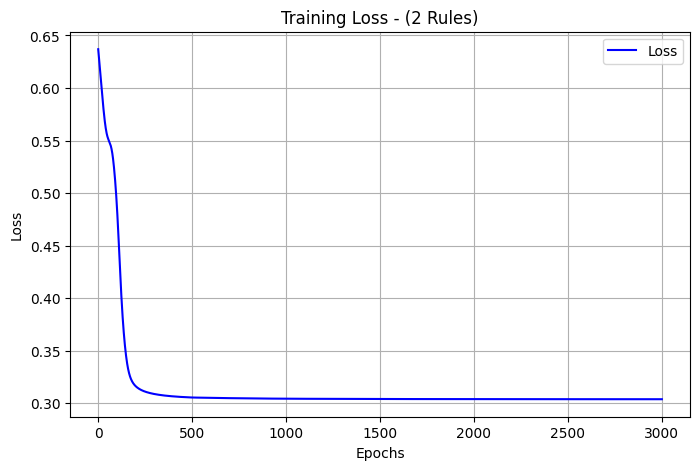

The most repeated rule is: 'h1 :- b3 and b4.'
Accuracy over training data: 0.994.
The most repeated rule is: 'h2 :- b1 and not(b2).'
Accuracy over training data: 0.998.

Final Rule:
h :- b3 and b4 OR b1 and not(b2).


In [3]:
from collections import Counter
# Parameters
Num_rules = 2
num_neurons_per_rule = 4
input_dim = 4
num_samples = 1000
num_epochs = 3000
num_restarts = 1
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()
# y_train = ((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5)).float()
# y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float()

# define y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float() using &
# y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5))).float()

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for num_rules in range(Num_rules):

    for restart in range(num_restarts):
        model_nsre = FuzzyDisjunctionNet(num_rules + 1, num_neurons_per_rule, input_dim)
        # criterion = nn.BCEWithLogitsLoss()
        criterion = nn.BCELoss()  # Use BCELoss for sigmoid outputs
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            # Cosine similarity loss
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            # Entropy regularization for exploration
            entropy_term = sum(model_nsre.entropies)

            total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term #+ 0.1*sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term + 0.1 * sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules + 1}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre
            best_num_rules = num_rules + 1  # Store the best number of rules
            # print(f"New best model found with {best_num_rules} rules and loss: {best_loss:.4f}")

# Load the best model
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim)
best_model.load_state_dict(best_state_dict)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss - ({best_num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)
# print("\nFinal Weights of the Network:")
# for i, weights in enumerate(Weights_nsre):
#     print(f"Rule {i+1}: {weights}")

# Rule interpretation
Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_entropy(pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


## Learning Structured Rules

Given this set of potential predicates $\{b_1(X_1, X_2), b_2(X_1), b_3(X_2, X_3), b_4(X_1, X_3)\}$ and the binary values for the head predicate $h(X_1, X_3)$, we aim to find the following target rule:

$h(X_1, X_3) :- b_1(X_1, X_2) \wedge \neg b_3(X_2, X_3)$,

where head variables are $X_1$ and $X_3$, and $X_2$ is an auxiliary variable. Each rule should satisfy these two conditions:

- Head variables should be present in the body of the rule.

- Auxiliary variables either should not be available in the body of the rule or should be available at least twice.

To enforce such conditions, we consider the following vector embeddings:

$X = [X_m]_{j=1}^m$, where $x_j$ is the probability of the existense of variable $X_j$ in the body predicates. The desired body variable embedding vector for the aforementioned target rule is $X_d = [X_1 = 1 , X_2 = 2, X_3 = 1, ..., X_m = 0]$

To find the variable embeddings for each rule, we firstly find the probablity of existense of a given predicate in the rule using its associated trainable weights. We know that each predicate $B_i$ has three weights $w_i^1$, $w_i^2$, and $w_i^3$ corresponding to $b_i$, $\neg b_i$, and $1$. Given this, we know that $w_i^3$ shows the probability of $B_i$ not being in the body of the rule. Therefore, $1-w_i^3$ is the probability of a given predicate appearing in the body of the rule at each training step, meaning $P = [1-w_i^3]_{i=1}^n$.

In the next step, we find the vector embeddings showing the existense of a given predicate in each potential predicate. Assume we have such potential predicates $\{B_i\}_{i=1}^n$ and variables $\{X_j\}_{j=1}^m$. If we assume that $v_{ij}$ is the probability of existense of variable $X_j$ in $B_i$, $v_{ij}$ is either 0 or 1, meaning $v_{ij} \in \{0, 1\}$. $V = [v_{ij}]_{n \times m}$ is a binary matrix describing the existense of a given variable in a given predicate.

Then the final probability vector is extracted using the following equation:
$M = P.V = [M_j]_{j=1}^m$


## Additional Loss Functions

1- Range Restricted Loss Function

$P_R = \prod_{i \in V_h} M[X_i]$

$L_R = MSE(P_R, 1)$

2- Connected Loss Function

$L_C = \Sigma_{j \in V_a} F(M[X_j])$

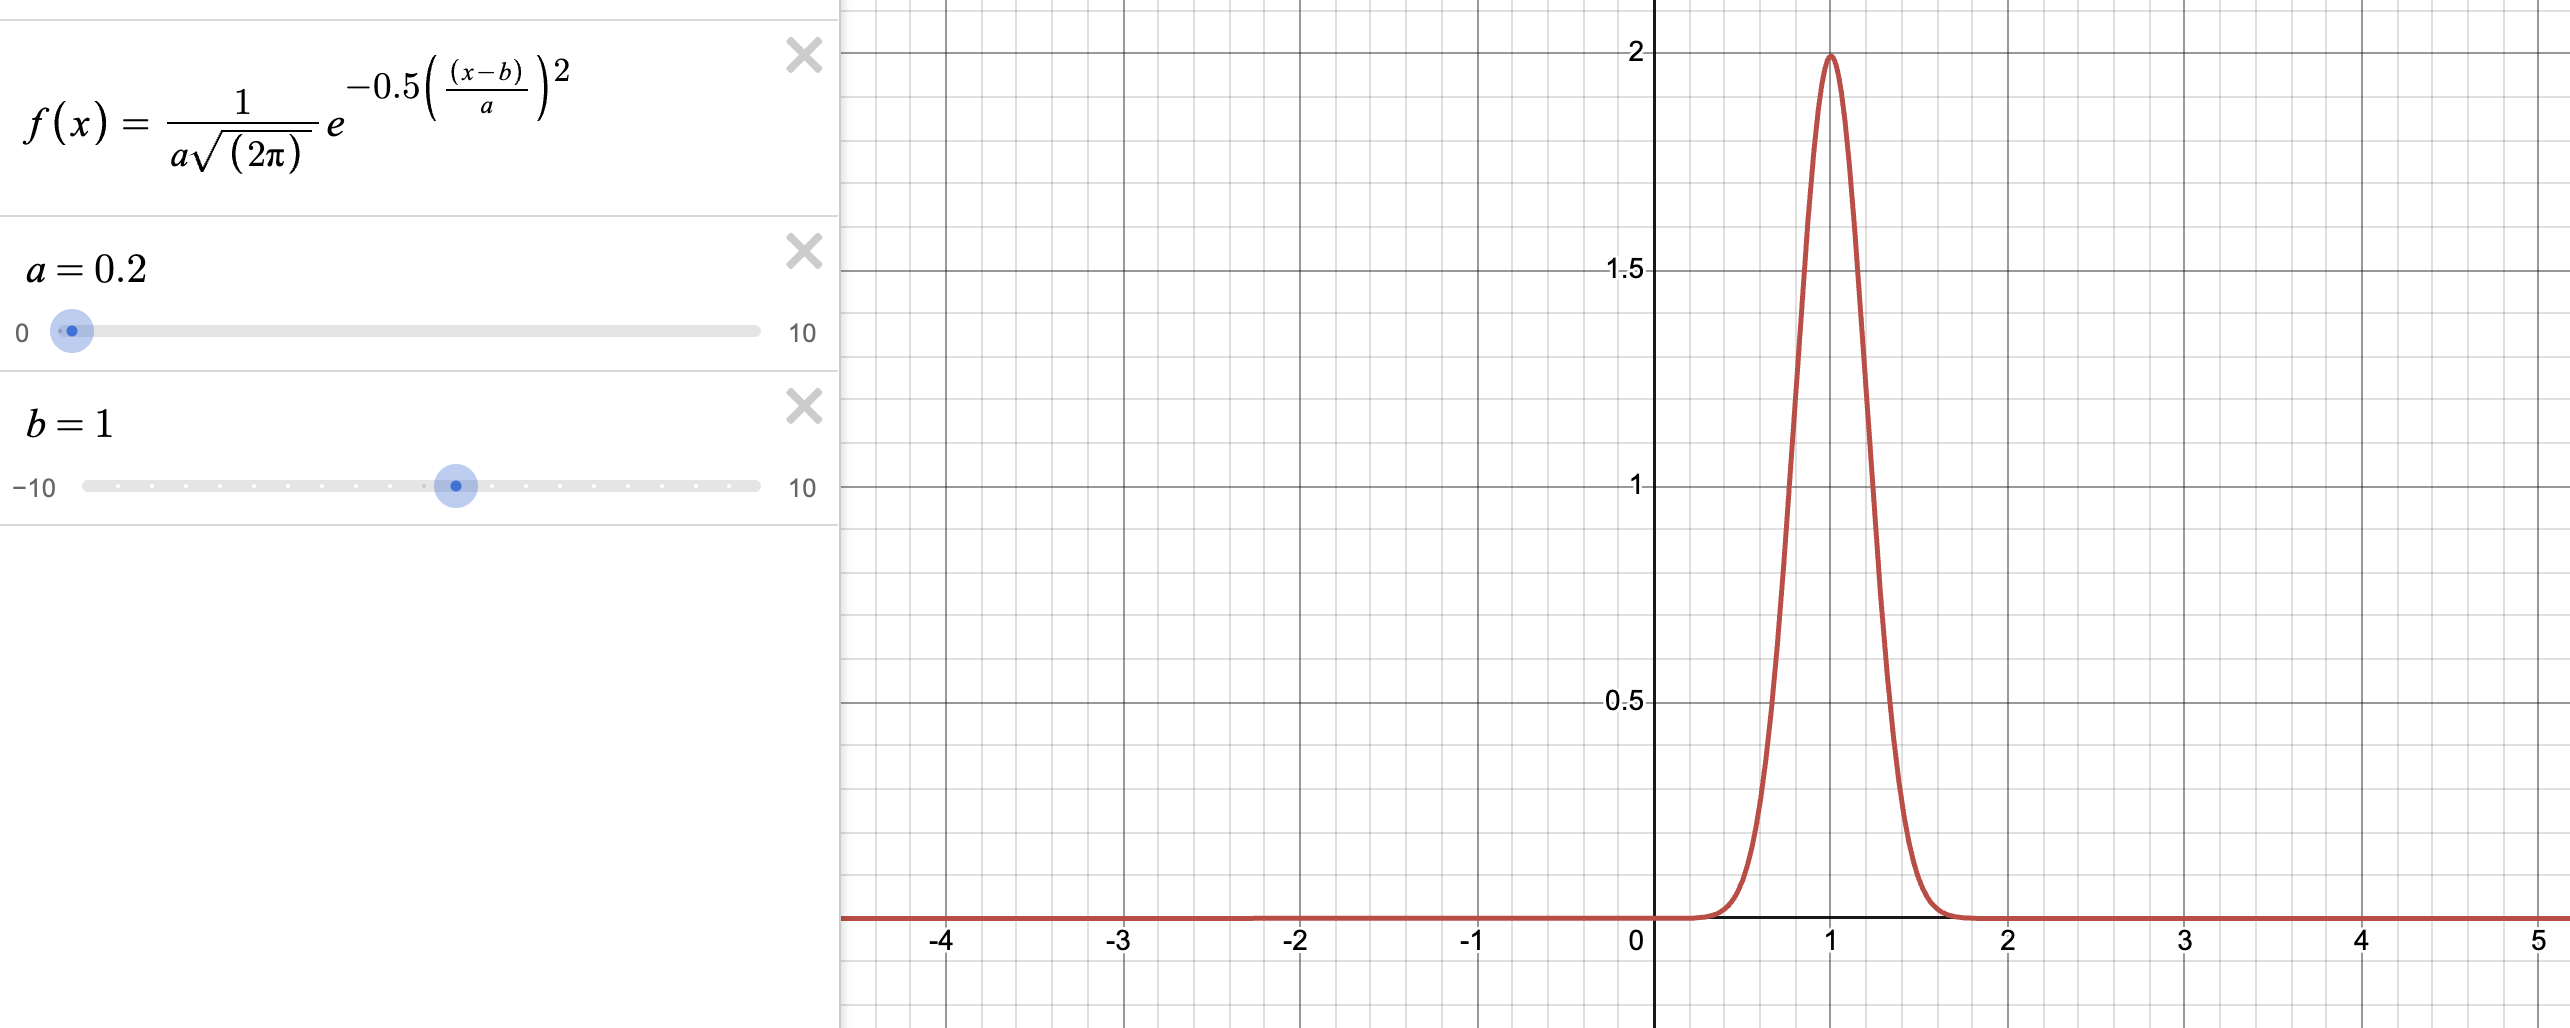

In [4]:
import torch
import re

def create_V_matrix(predicates):
    # Extract all variable names
    variable_set = set()
    predicate_vars = []
    for pred in predicates:
        # Extract variables inside parentheses
        vars_in_pred = re.findall(r'\((.*?)\)', pred)
        if vars_in_pred:
            vars_list = [v.strip() for v in vars_in_pred[0].split(',')]
        else:
            vars_list = []
        predicate_vars.append(vars_list)
        variable_set.update(vars_list)
    # Sort variables for consistent column order
    variables = sorted(variable_set, key=lambda x: (int(x[1:]) if x[1:].isdigit() else x))
    var_idx = {v: i for i, v in enumerate(variables)}
    # Build the matrix
    V = torch.zeros((len(predicates), len(variables)), dtype=torch.float32)
    for i, vars_list in enumerate(predicate_vars):
        for v in vars_list:
            V[i, var_idx[v]] = 1.0
    return V, variables

# Network for Structured Rules

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 10.0  # Example value for beta
# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

# Define FuzzyDisjunctionNet
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, variable_matrix):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.V = variable_matrix
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        self.M_matrices = []
        rule_outputs = []

        for i, rule in enumerate(self.rules):
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            P = []
            for j, neuron in enumerate(rule):
                xi = x[:, [j % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                P.append(1.0 - weights[2])  # 1 - w3

            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)

            P_tensor = torch.stack(P)
            M = torch.matmul(P_tensor, self.V)
            self.M_matrices.append(M)

            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(5*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(5*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum

        return activated_output

V_matrix:
 tensor([[1., 1., 0.],
        [1., 0., 0.],
        [0., 1., 1.],
        [1., 0., 1.]])
Variable order: ['X1', 'X2', 'X3']
Restart 1/1 Final Loss: 0.2775


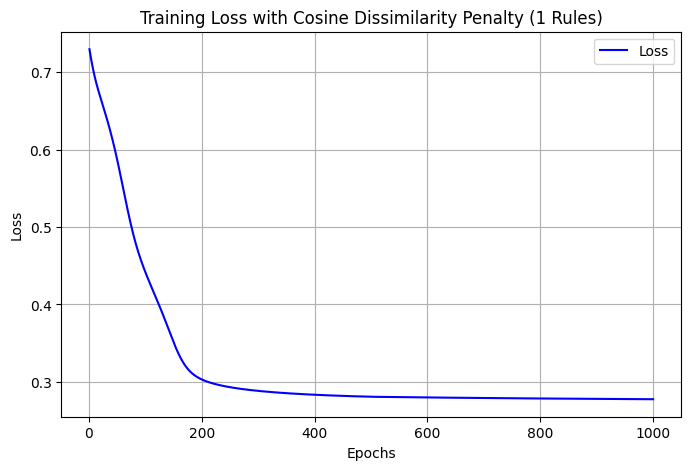

The most repeated rule is: 'h1 :- not(b1(X1, X2)) and b3(X2, X3).'
It appears 494 times out of 500.

Final Rule:
h :- not(b1(X1, X2)) and b3(X2, X3).

Final M matrices:
M1: [1.3938586711883545, 1.9831154346466064, 1.1938889026641846]


In [ ]:
# Re-execution after kernel reset

import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter

# Parameters
num_rules = 1
num_neurons_per_rule = 4
input_dim = num_neurons_per_rule
num_samples = 500
num_epochs = 1000
num_restarts = 1
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
# put the second column same as the first column
y_train = (((1 - X_train[:, 0]) > 0.5) & (X_train[:, 2] > 0.5)).float()

# Body predicates and their variables
# B = {b1(X1, X2), b2(X1), b3(X2, X3), b4(X1, X3)}
predicates = ["b1(X1, X2)", "b2(X1)", "b3(X2, X3)", "b4(X1, X3)"]
V_matrix, variable_order = create_V_matrix(predicates)
print("V_matrix:\n", V_matrix)
print("Variable order:", variable_order)

head_vars = [0, 2] # X1 and X3 are the head variables
connected_vars = [1]  # X2 is the only auxiliary variable


# Cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, V_matrix)
    # criterion = nn.BCEWithLogitsLoss()
    criterion = nn.BCELoss()
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Compute range resticted loss -> the probability of the head variables being present in the rule
        M = model_nsre.M_matrices
        # Find the corresponding values of M to head variables (here Variable 1 and 3)

        M_head = [M[i][head_vars] for i in range(num_rules)]
        # Multiply the elements of M_head
        head_var_probs = torch.prod(torch.stack(M_head), dim=0)
        # Find the loss as the mean of the head variable probabilities with 1 (the probability of the head variable being present)
        range_restricted_loss = torch.mean(torch.sigmoid(-10 * (head_var_probs - 0.5)))
        # print(f"Range Restricted Loss: {range_restricted_loss.item()}")

        # Compute the connected loss -> auxiliary variables should be present in the rule either zero or more than one time
        # The only auxiliary variable is X2
        M_connected = [M[i][connected_vars] for i in range(num_rules)]

        # Compute this for each auxiliary variable: F(x) = normal distribution with mean 1 and std 0.2
        import math
        Sum_Fx = 0.0
        for i, M in enumerate(M_connected):
            mean = 1.0
            std = 0.2
            Sum_Fx += torch.exp(-0.5 * ((M - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))
        connected_loss = 0.5 * Sum_Fx / len(M_connected)  # Average over all rules

        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term + 0.1 * range_restricted_loss + 0.1 * connected_loss
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load best model and compute M
best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, V_matrix)
best_model.load_state_dict(best_state_dict)
_ = best_model(X_train)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Rule interpretation
Predicate_values = X_train
input_dim = 4

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {M}")

## What if we have more than one rule?

V_matrix:
 tensor([[1., 1., 0.],
        [0., 1., 1.],
        [1., 0., 0.],
        [0., 0., 1.]])
Variable order: ['X1', 'X2', 'X3']
Restart 1/3 Final Loss: 0.3082
Restart 2/3 Final Loss: 0.3082
Restart 3/3 Final Loss: 0.3082


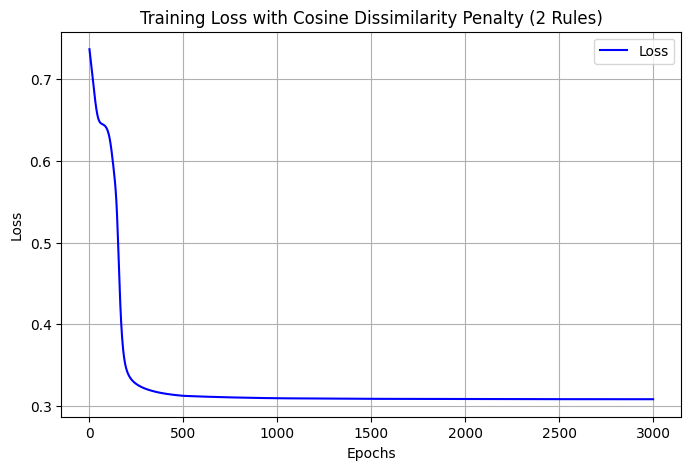


Final M matrices:
M1: [1. 2. 1.]
M2: [1. 0. 1.]

Final V matrix:
[[1. 1. 0.]
 [0. 1. 1.]
 [1. 0. 0.]
 [0. 0. 1.]]
The most repeated rule is: 'h1 :- b1(X1, X2) and not(b2(X2, X3)).'
It appears 1990 times out of 2000.
The most repeated rule is: 'h2 :- b3(X1) and b4(X3).'
It appears 1992 times out of 2000.

Final Rule:
h :- b1(X1, X2) and not(b2(X2, X3)) OR b3(X1) and b4(X3).


In [ ]:
# Re-execution after kernel reset

import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter
import math

# Parameters
num_rules = 2
num_neurons_per_rule = 4
input_dim = num_neurons_per_rule
num_samples = 2000
num_epochs = 3000
num_restarts = 3
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
# put the second column same as the first column
# X_train[:, 1] = X_train[:, 0]
# y_train = (((1 - X_train[:, 0]) * X_train[:, 1] > 0.25) | ((X_train[:, 2] * X_train[:, 3]) > 0.25)).float()
y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()

# Target body predicates and their variables
# B = {b1(X1, X2), b2(X2, X3), b3(X1), b4(X3)}
# We assume the model doesn't know the variables of the predicates beforehand, so we want to learn them
predicates = ["b1(X1, X2)", "b2(X2, X3)", "b3(X1)", "b4(X3)"]
V_matrix, variable_order = create_V_matrix(predicates)
print("V_matrix:\n", V_matrix)
print("Variable order:", variable_order)

# Variables
variables = ["X1", "X2", "X3"]  # Assuming we have 3 variables
# Head variables for the rule
head_variables = ["X1", "X3"]  # Assuming the head variables are X1 and X3
# Define head variables indices
# Assuming the head variables are X1 and X3, we can define their indices
head_vars = [0, 2]  # Assuming the head variables are X1 and X3
connected_vars = [1]  # Assuming X2 is the only auxiliary variable

# print("V_matrix:\n", V_matrix)
# print("Variable order:", variable_order)

# Cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, V_matrix)
    # criterion = nn.BCEWithLogitsLoss()
    criterion = nn.BCELoss()
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Compute range resticted loss -> the probability of the head variables being present in the rule
        M = model_nsre.M_matrices
        # Find the corresponding values of M to head variables (here Variable 1 and 3)
        M_head = [M[i][head_vars] for i in range(num_rules)]
        # Multiply the elements of M_head
        head_var_probs = torch.prod(torch.stack(M_head), dim=0)
        # Find the loss as the mean of the head variable probabilities with 1 (the probability of the head variable being present)
        range_restricted_loss = torch.mean(torch.sigmoid(-10 * (head_var_probs - 0.5)))
        # print(f"Range Restricted Loss: {range_restricted_loss.item()}")

        # Compute the connected loss -> auxiliary variables should be present in the rule either zero or more than one time
        M_connected = [M[i][connected_vars] for i in range(num_rules)]
        # Compute this for each auxiliary variable: F(x) = normal distribution with mean 1 and std 0.2
        Sum_Fx = 0.0
        for i, M in enumerate(M_connected):
            mean = 1.0
            std = 0.2
            Sum_Fx += torch.exp(-0.5 * ((M - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))
        connected_loss = 0.5 * Sum_Fx / len(M_connected)  # Average over all rules

        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term + 0.01 * range_restricted_loss + 0.01 * connected_loss
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

        # print V matrix
        # print("V matrix:", model_nsre.V.detach().numpy())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load best model and compute M
best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, V_matrix)
best_model.load_state_dict(best_state_dict)
_ = best_model(X_train)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]
V_matrix = best_model.V.detach().numpy().tolist()

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {np.round(M)}")

print("\nFinal V matrix:")
print(np.round(V_matrix))

# Rule interpretation
Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


## Find the rule for even/odd numbers

## Find the rule for grandparent/2 relationships

## Write a Function showing if some of the predicates are correlated

## How to add constraints to the network?